Found 74 XYE files.


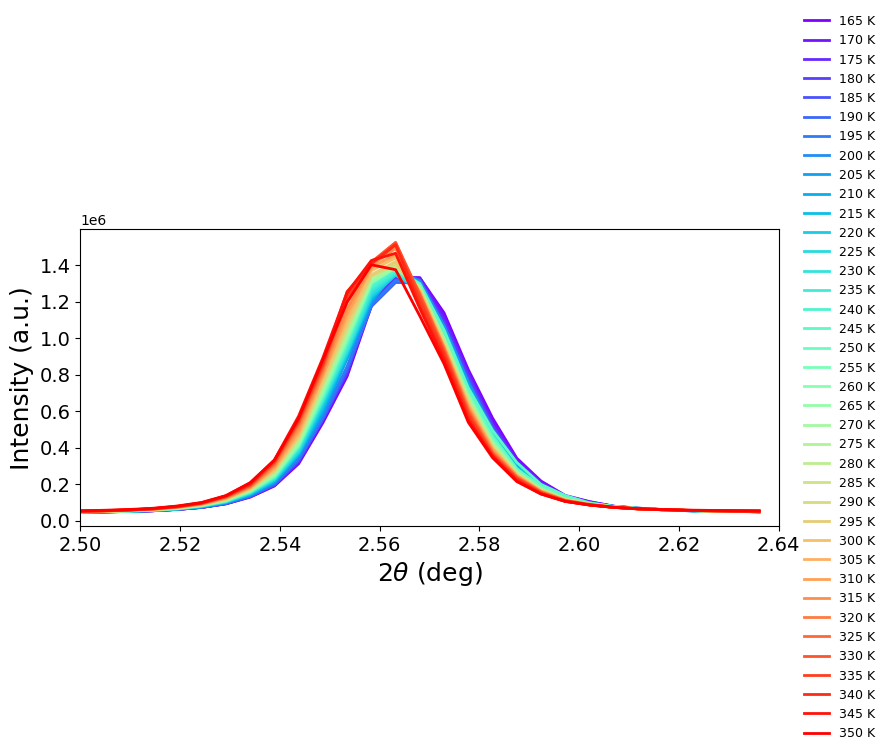

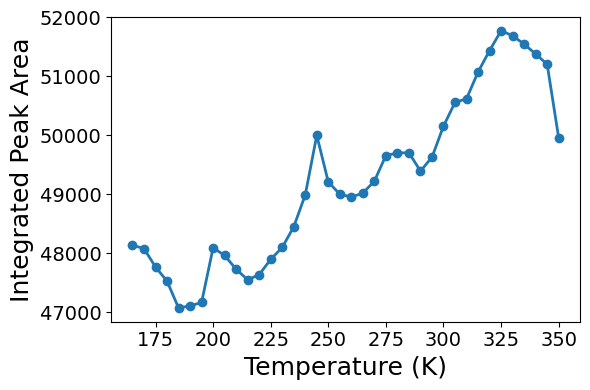

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re

# ====================================================
# User parameters
# ====================================================

# 2theta range
theta_min = 2.5
theta_max = 2.64

# Temperature range (K)
T_min = 165
T_max = 350

# Number of header lines
header_lines = 3

# ====================================================
# Read all files in current directory
# ====================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")

if len(files) == 0:
    raise FileNotFoundError("No .xye or .xye.txt files found.")

# ====================================================
# Containers
# ====================================================

temps = []
areas = []
patterns = []

# ====================================================
# Read every file
# ====================================================

for file in files:

    filename = os.path.basename(file)

    # --------------------------------------------
    # Extract temperature
    # --------------------------------------------
    m = re.search(r'_(\d+(?:\.\d+)?)K', filename)

    if m is None:
        print(f"Temperature not found in {filename}")
        continue

    T = float(m.group(1))

    # Temperature filter
    if (T < T_min) or (T > T_max):
        continue

    # --------------------------------------------
    # Read XYE file
    # --------------------------------------------
    data = np.loadtxt(file, skiprows=header_lines)

    theta = data[:, 0]
    intensity = data[:, 1]

    # --------------------------------------------
    # Theta range
    # --------------------------------------------
    mask = (theta >= theta_min) & (theta <= theta_max)

    theta = theta[mask]
    intensity = intensity[mask]

    if len(theta) == 0:
        print(f"No data in chosen theta range for {filename}")
        continue

    # --------------------------------------------
    # Integrated area
    # --------------------------------------------
    area = np.trapezoid(intensity, x=theta)

    temps.append(T)
    areas.append(area)

    patterns.append((T, theta, intensity))

# ====================================================
# Sort by temperature
# ====================================================

temps = np.array(temps)
areas = np.array(areas)

idx = np.argsort(temps)

temps = temps[idx]
areas = areas[idx]
patterns = [patterns[i] for i in idx]

# ====================================================
# Plot all diffraction patterns
# ====================================================

plt.figure(figsize=(9,6))

colors = plt.get_cmap('rainbow')(np.linspace(0,1,len(patterns)))

for i,(T,theta,intensity) in enumerate(patterns):

    plt.plot(
        theta,
        intensity,
        lw=2,
        color=colors[i],
        label=f"{T:.0f} K"
    )

plt.xlabel(r"$2\theta$ (deg)", fontsize=18)
plt.ylabel("Intensity (a.u.)", fontsize=18)

plt.xlim(theta_min, theta_max)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(
    loc='center left',
    bbox_to_anchor=(1.02,0.5),
    fontsize=9,
    frameon=False,
    ncol=1
)

plt.tight_layout()

plt.savefig(
    "XRD_TemperatureSeries.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ====================================================
# Plot Integrated Area vs Temperature
# ====================================================

plt.figure(figsize=(6,4))

plt.plot(
    temps,
    areas,
    '-o',
    linewidth=2,
    markersize=6
)

plt.xlabel("Temperature (K)", fontsize=18)
plt.ylabel("Integrated Peak Area", fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()

plt.savefig(
    "IntegratedArea_vs_Temperature.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [3]:
import glob
import os

print("Files found:", len(files))

for f in files:
    print(os.path.basename(f))

Files found: 0


Found 74 XYE files.


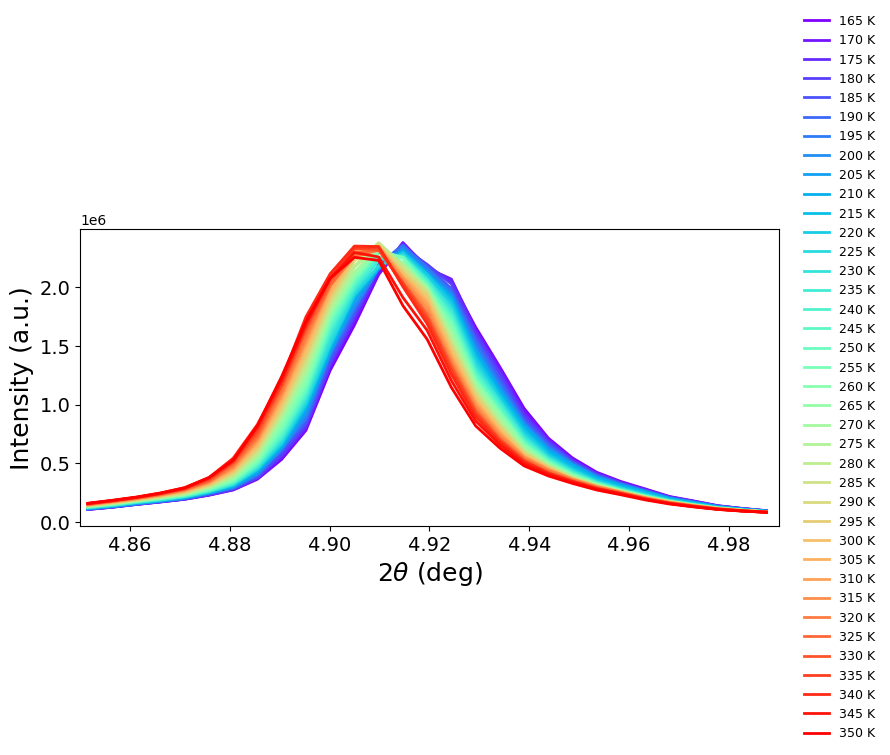

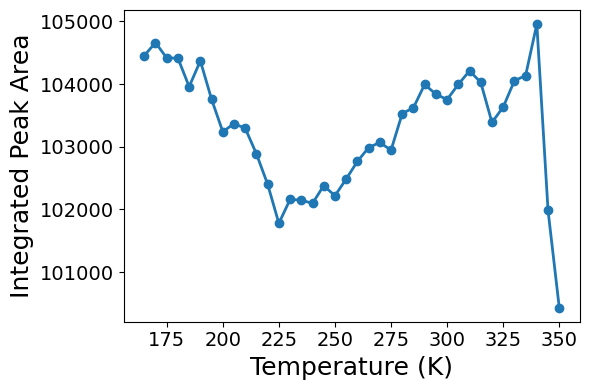

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re

# ====================================================
# User parameters
# ====================================================

# 2theta range
theta_min = 4.85
theta_max = 4.99

# Temperature range (K)
T_min = 165
T_max = 350

# Number of header lines
header_lines = 3

# ====================================================
# Read all files in current directory
# ====================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")

if len(files) == 0:
    raise FileNotFoundError("No .xye or .xye.txt files found.")

# ====================================================
# Containers
# ====================================================

temps = []
areas = []
patterns = []

# ====================================================
# Read every file
# ====================================================

for file in files:

    filename = os.path.basename(file)

    # --------------------------------------------
    # Extract temperature
    # --------------------------------------------
    m = re.search(r'_(\d+(?:\.\d+)?)K', filename)

    if m is None:
        print(f"Temperature not found in {filename}")
        continue

    T = float(m.group(1))

    # Temperature filter
    if (T < T_min) or (T > T_max):
        continue

    # --------------------------------------------
    # Read XYE file
    # --------------------------------------------
    data = np.loadtxt(file, skiprows=header_lines)

    theta = data[:, 0]
    intensity = data[:, 1]

    # --------------------------------------------
    # Theta range
    # --------------------------------------------
    mask = (theta >= theta_min) & (theta <= theta_max)

    theta = theta[mask]
    intensity = intensity[mask]

    if len(theta) == 0:
        print(f"No data in chosen theta range for {filename}")
        continue

    # --------------------------------------------
    # Integrated area
    # --------------------------------------------
    area = np.trapezoid(intensity, x=theta)

    temps.append(T)
    areas.append(area)

    patterns.append((T, theta, intensity))

# ====================================================
# Sort by temperature
# ====================================================

temps = np.array(temps)
areas = np.array(areas)

idx = np.argsort(temps)

temps = temps[idx]
areas = areas[idx]
patterns = [patterns[i] for i in idx]

# ====================================================
# Plot all diffraction patterns
# ====================================================

plt.figure(figsize=(9,6))

colors = plt.get_cmap('rainbow')(np.linspace(0,1,len(patterns)))

for i,(T,theta,intensity) in enumerate(patterns):

    plt.plot(
        theta,
        intensity,
        lw=2,
        color=colors[i],
        label=f"{T:.0f} K"
    )

plt.xlabel(r"$2\theta$ (deg)", fontsize=18)
plt.ylabel("Intensity (a.u.)", fontsize=18)

plt.xlim(theta_min, theta_max)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(
    loc='center left',
    bbox_to_anchor=(1.02,0.5),
    fontsize=9,
    frameon=False,
    ncol=1
)

plt.tight_layout()

plt.savefig(
    "XRD_TemperatureSeries.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ====================================================
# Plot Integrated Area vs Temperature
# ====================================================

plt.figure(figsize=(6,4))

plt.plot(
    temps,
    areas,
    '-o',
    linewidth=2,
    markersize=6
)

plt.xlabel("Temperature (K)", fontsize=18)
plt.ylabel("Integrated Peak Area", fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()

plt.savefig(
    "IntegratedArea_vs_Temperature.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Found 74 XYE files.

===== XYE NORMALIZATION =====
Theta range 1: 2.5–2.64°
Maximum area 1 = 51775.565246
Theta range 2: 4.85–4.99°
Maximum area 2 = 104957.233757


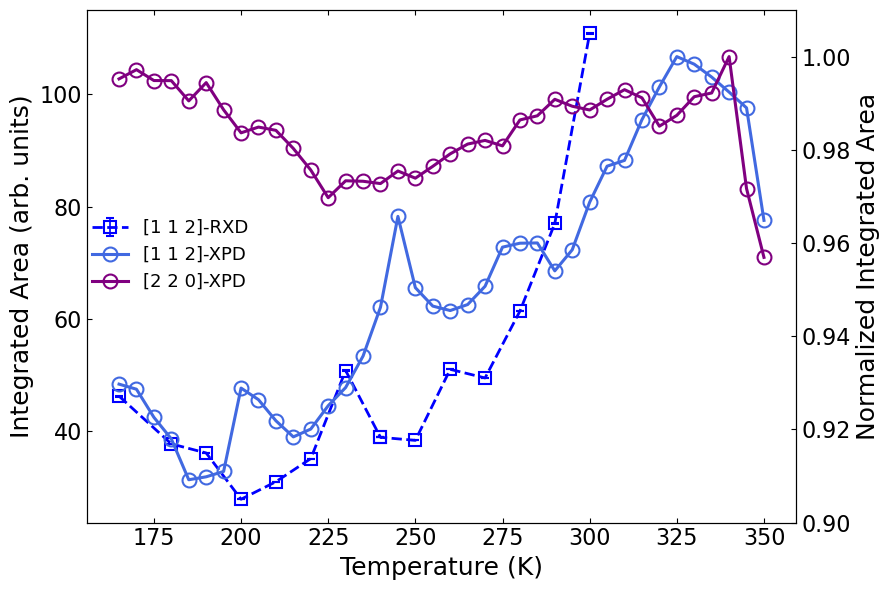

In [56]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re
import pandas as pd

# ============================================================
# USER PARAMETERS
# ============================================================

# ------------------------------------------------------------
# XYE DATA: first theta range
# ------------------------------------------------------------
theta1_min = 2.50
theta1_max = 2.64

# ------------------------------------------------------------
# XYE DATA: second theta range
# ------------------------------------------------------------
theta2_min = 4.85
theta2_max = 4.99

# ------------------------------------------------------------
# Temperature range for XYE files
# ------------------------------------------------------------
T_min = 165
T_max = 350

# Number of header lines in XYE files
header_lines = 3

# ------------------------------------------------------------
# Excel file
# ------------------------------------------------------------
excel_file = "Sr2IrO4_July2026__112 Structural Peak_Int. Area.xlsx"

# Excel column names
temp_column = "T(K)"
area_column = "Int. Area."


# ============================================================
# READ EXCEL DATA
# ============================================================

df = pd.read_excel(excel_file)

required_columns = {temp_column, area_column}

if not required_columns.issubset(df.columns):
    raise ValueError(
        f"Excel file must contain columns: {required_columns}"
    )

# Temperature
T_excel = pd.to_numeric(
    df[temp_column],
    errors="coerce"
).values

# ------------------------------------------------------------
# Extract area and error from:
#
# 110.85918 ± 0.02349
# ------------------------------------------------------------

area_split = (
    df[area_column]
    .astype(str)
    .str.split(r"\s*±\s*", expand=True)
)

area_excel = pd.to_numeric(
    area_split[0],
    errors="coerce"
).values

area_error = pd.to_numeric(
    area_split[1],
    errors="coerce"
).values

# Remove invalid values
mask_excel = (
    np.isfinite(T_excel)
    & np.isfinite(area_excel)
    & np.isfinite(area_error)
    & (area_error > 0)
)

T_excel = T_excel[mask_excel]
area_excel = area_excel[mask_excel]
area_error = area_error[mask_excel]

# Sort by temperature
idx_excel = np.argsort(T_excel)

T_excel = T_excel[idx_excel]
area_excel = area_excel[idx_excel]
area_error = area_error[idx_excel]


# ============================================================
# READ ALL XYE FILES
# ============================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")

if len(files) == 0:
    raise FileNotFoundError(
        "No .xye or .xye.txt files found."
    )


# ============================================================
# CONTAINERS
# ============================================================

temps1 = []
areas1 = []

temps2 = []
areas2 = []


# ============================================================
# READ EACH XYE FILE
# ============================================================

for file in files:

    filename = os.path.basename(file)

    # --------------------------------------------------------
    # Extract temperature from filename
    # Example:
    # something_225K.xye
    # --------------------------------------------------------

    m = re.search(
        r'_(\d+(?:\.\d+)?)K',
        filename
    )

    if m is None:
        print(
            f"Temperature not found in {filename}"
        )
        continue

    T = float(m.group(1))

    # Temperature filter
    if T < T_min or T > T_max:
        continue

    # --------------------------------------------------------
    # Read XYE file
    # --------------------------------------------------------

    try:
        data = np.loadtxt(
            file,
            skiprows=header_lines
        )
    except Exception as e:
        print(
            f"Could not read {filename}: {e}"
        )
        continue

    theta = data[:, 0]
    intensity = data[:, 1]

    # ========================================================
    # FIRST THETA RANGE
    # ========================================================

    mask1 = (
        (theta >= theta1_min)
        & (theta <= theta1_max)
    )

    theta1 = theta[mask1]
    intensity1 = intensity[mask1]

    if len(theta1) > 1:

        area1 = np.trapezoid(
            intensity1,
            x=theta1
        )

        temps1.append(T)
        areas1.append(area1)

    # ========================================================
    # SECOND THETA RANGE
    # ========================================================

    mask2 = (
        (theta >= theta2_min)
        & (theta <= theta2_max)
    )

    theta2 = theta[mask2]
    intensity2 = intensity[mask2]

    if len(theta2) > 1:

        area2 = np.trapezoid(
            intensity2,
            x=theta2
        )

        temps2.append(T)
        areas2.append(area2)


# ============================================================
# CONVERT TO NUMPY ARRAYS
# ============================================================

temps1 = np.array(temps1)
areas1 = np.array(areas1)

temps2 = np.array(temps2)
areas2 = np.array(areas2)


# ============================================================
# SORT BY TEMPERATURE
# ============================================================

idx1 = np.argsort(temps1)

temps1 = temps1[idx1]
areas1 = areas1[idx1]


idx2 = np.argsort(temps2)

temps2 = temps2[idx2]
areas2 = areas2[idx2]


# ============================================================
# NORMALIZE EACH XYE CURVE INDEPENDENTLY
# ============================================================

if len(areas1) == 0:
    raise ValueError(
        "No data found in the first theta range."
    )

if len(areas2) == 0:
    raise ValueError(
        "No data found in the second theta range."
    )


# Normalize to maximum integrated area
areas1_norm = areas1 / np.max(areas1)

areas2_norm = areas2 / np.max(areas2)


# ============================================================
# PRINT NORMALIZATION INFORMATION
# ============================================================

print("\n===== XYE NORMALIZATION =====")

print(
    f"Theta range 1: "
    f"{theta1_min}–{theta1_max}°"
)

print(
    f"Maximum area 1 = "
    f"{np.max(areas1):.6f}"
)

print(
    f"Theta range 2: "
    f"{theta2_min}–{theta2_max}°"
)

print(
    f"Maximum area 2 = "
    f"{np.max(areas2):.6f}"
)


# ============================================================
# TWO-Y-AXIS PLOT
# ============================================================

fig, ax_left = plt.subplots(
    figsize=(9, 6)
)

# ------------------------------------------------------------
# LEFT Y-AXIS
# Excel integrated area
# ------------------------------------------------------------

ax_left.errorbar(
    T_excel,
    area_excel,
    yerr=area_error,

    fmt='--s',                  # connected squares
    color='blue',      # connected line
    markerfacecolor='none',
    markeredgecolor='blue',    # slightly different navy for symbols
    markeredgewidth=1.5,

    ecolor='blue',     # error bars
    elinewidth=1.2,
    capsize=3,

    markersize=8,
    linewidth=2.0,

    label='[1 1 2]-RXD'
)

ax_left.set_xlabel(
    "Temperature (K)",
    fontsize=18
)

ax_left.set_ylabel(
    "Integrated Area (arb. units)",
    fontsize=18
)

ax_left.tick_params(
    axis='both',
    which='major',
    labelsize=16,
    direction='in'
)


# ============================================================
# RIGHT Y-AXIS
# ============================================================

ax_right = ax_left.twinx()


# ------------------------------------------------------------
# Theta range 1
# ------------------------------------------------------------

ax_right.plot(
    temps1,
    areas1_norm,

    '-o',

    color='royalblue',

    linewidth=2.2,
    markersize=10,

    markerfacecolor='none',
    markeredgecolor='royalblue',
    markeredgewidth=1.5,

    label='[1 1 2]-XPD'
)



# ------------------------------------------------------------
# Theta range 2
# ------------------------------------------------------------

curve2 = ax_right.plot(
    temps2,
    areas2_norm,

    '-o',
    color='purple',

    linewidth=2.2,
    markersize=10,

    # Open squares
   markerfacecolor='none',
    markeredgecolor='purple',
    markeredgewidth=1.5,

    label='[2 2 0]-XPD'
)[0]


ax_right.set_ylabel(
    "Normalized Integrated Area",
    fontsize=18
)

ax_right.tick_params(
    axis='y',
    which='major',
    labelsize=16,
    direction='in'
)

# Normalized scale
ax_right.set_ylim(
    0.9,
    1.01
)


# ============================================================
# COMBINED LEGEND
# ============================================================

ax_left.legend(
    handles_left + handles_right,
    labels_left + labels_right,
    loc='lower right',
    bbox_to_anchor=(0.25, 0.42),
    fontsize=13,
    frameon=False
)


# ============================================================
# GENERAL FIGURE SETTINGS
# ============================================================

ax_left.tick_params(
    top=True,
    direction='in'
)

ax_right.tick_params(
    direction='in'
)

# No grid
ax_left.grid(False)
ax_right.grid(False)

plt.tight_layout()


# ============================================================
# SAVE FIGURE
# ============================================================

plt.savefig(
    "Integrated_Area_TwoTheta_Comparison.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Found 74 XYE files.


/tmp/ipykernel_196075/3911914224.py:142: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


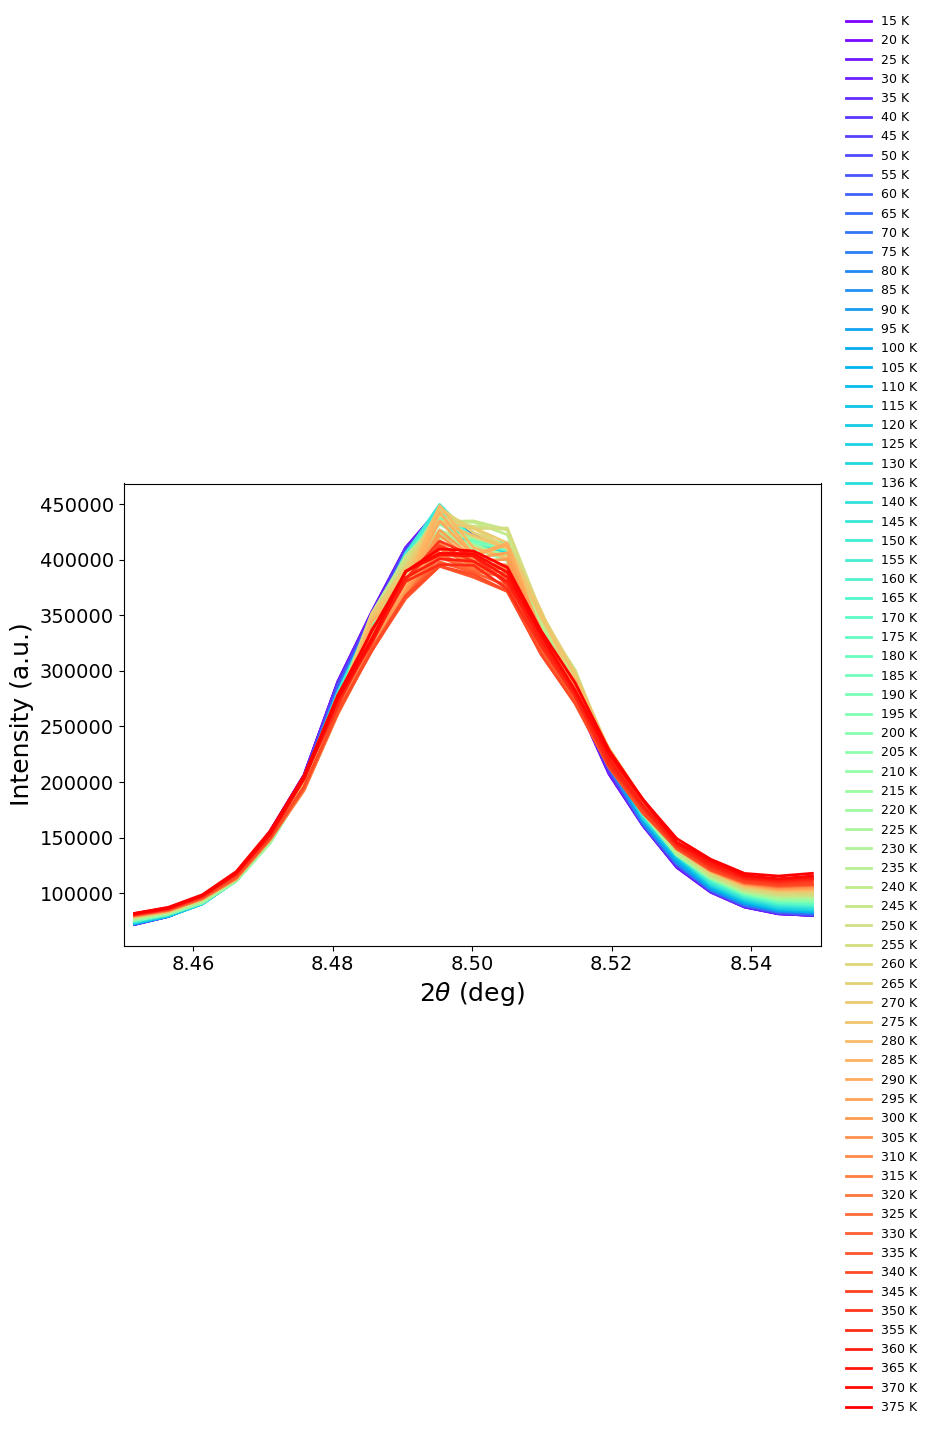

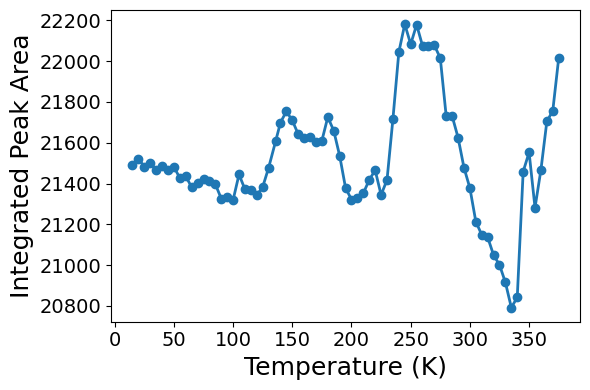

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re

# ====================================================
# User parameters
# ====================================================

# 2theta range
theta_min = 8.45
theta_max = 8.55

# Temperature range (K)
T_min = 15
T_max = 375

# Number of header lines
header_lines = 3

# ====================================================
# Read all files in current directory
# ====================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")

if len(files) == 0:
    raise FileNotFoundError("No .xye or .xye.txt files found.")

# ====================================================
# Containers
# ====================================================

temps = []
areas = []
patterns = []

# ====================================================
# Read every file
# ====================================================

for file in files:

    filename = os.path.basename(file)

    # --------------------------------------------
    # Extract temperature
    # --------------------------------------------
    m = re.search(r'_(\d+(?:\.\d+)?)K', filename)

    if m is None:
        print(f"Temperature not found in {filename}")
        continue

    T = float(m.group(1))

    # Temperature filter
    if (T < T_min) or (T > T_max):
        continue

    # --------------------------------------------
    # Read XYE file
    # --------------------------------------------
    data = np.loadtxt(file, skiprows=header_lines)

    theta = data[:, 0]
    intensity = data[:, 1]

    # --------------------------------------------
    # Theta range
    # --------------------------------------------
    mask = (theta >= theta_min) & (theta <= theta_max)

    theta = theta[mask]
    intensity = intensity[mask]

    if len(theta) == 0:
        print(f"No data in chosen theta range for {filename}")
        continue

    # --------------------------------------------
    # Integrated area
    # --------------------------------------------
    area = np.trapezoid(intensity, x=theta)

    temps.append(T)
    areas.append(area)

    patterns.append((T, theta, intensity))

# ====================================================
# Sort by temperature
# ====================================================

temps = np.array(temps)
areas = np.array(areas)

idx = np.argsort(temps)

temps = temps[idx]
areas = areas[idx]
patterns = [patterns[i] for i in idx]

# ====================================================
# Plot all diffraction patterns
# ====================================================

plt.figure(figsize=(9,6))

colors = plt.get_cmap('rainbow')(np.linspace(0,1,len(patterns)))

for i,(T,theta,intensity) in enumerate(patterns):

    plt.plot(
        theta,
        intensity,
        lw=2,
        color=colors[i],
        label=f"{T:.0f} K"
    )

plt.xlabel(r"$2\theta$ (deg)", fontsize=18)
plt.ylabel("Intensity (a.u.)", fontsize=18)

plt.xlim(theta_min, theta_max)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(
    loc='center left',
    bbox_to_anchor=(1.02,0.5),
    fontsize=9,
    frameon=False,
    ncol=1
)

plt.tight_layout()

plt.savefig(
    "XRD_TemperatureSeries.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ====================================================
# Plot Integrated Area vs Temperature
# ====================================================

plt.figure(figsize=(6,4))

plt.plot(
    temps,
    areas,
    '-o',
    linewidth=2,
    markersize=6
)

plt.xlabel("Temperature (K)", fontsize=18)
plt.ylabel("Integrated Peak Area", fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()

plt.savefig(
    "IntegratedArea_vs_Temperature.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Found 74 XYE files.


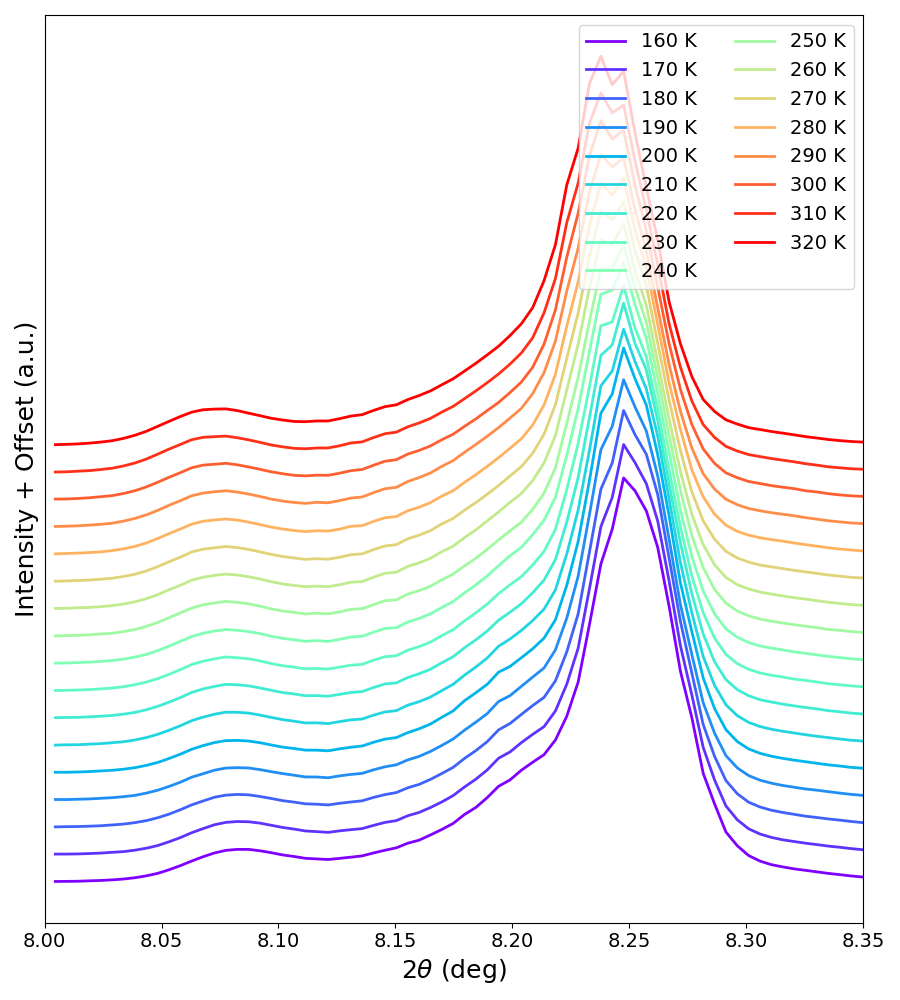

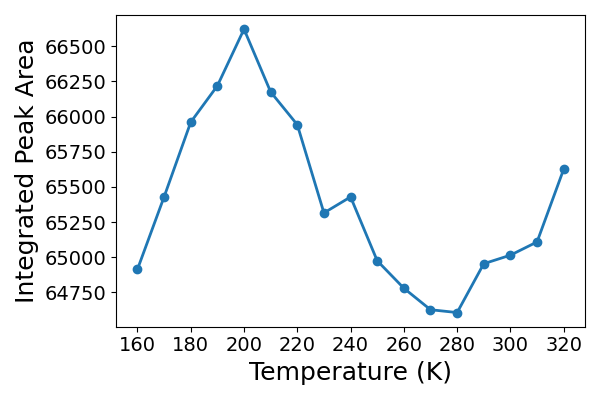

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re

# ====================================================
# User parameters
# ====================================================

# 2theta range
theta_min = 8.00
theta_max = 8.35

# Temperature range (K)
T_min = 160
T_max = 320

# Number of header lines
header_lines = 3

# --- ADDED: Waterfall Offset Parameter ---
# Adjust this vertical step size based on your peak intensities
vertical_step = 50000  

# ====================================================
# Read all files in current directory
# ====================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")

if len(files) == 0:
    raise FileNotFoundError("No .xye or .xye.txt files found.")

# ====================================================
# Containers
# ====================================================

temps = []
areas = []
patterns = []

# ====================================================
# Read every file
# ====================================================

for file in files:

    filename = os.path.basename(file)

    # --------------------------------------------
    # Extract temperature
    # --------------------------------------------
    m = re.search(r'_(\d+(?:\.\d+)?)K', filename)

    if m is None:
        print(f"Temperature not found in {filename}")
        continue

    T = float(m.group(1))

    # Temperature filter
    if (T < T_min) or (T > T_max):
        continue

    # --- MODIFIED: Filter for 10 K intervals ---
    # Checks if the temperature is within 0.5 K of a 10 K step (e.g., 20K, 30K...)
    if not np.isclose(T % 10, 0, atol=0.5) and not np.isclose(T % 10, 10, atol=0.5):
        continue

    # --------------------------------------------
    # Read XYE file
    # --------------------------------------------
    data = np.loadtxt(file, skiprows=header_lines)

    theta = data[:, 0]
    intensity = data[:, 1]

    # --------------------------------------------
    # Theta range
    # --------------------------------------------
    mask = (theta >= theta_min) & (theta <= theta_max)

    theta = theta[mask]
    intensity = intensity[mask]

    if len(theta) == 0:
        print(f"No data in chosen theta range for {filename}")
        continue

    # --------------------------------------------
    # Integrated area
    # --------------------------------------------
    area = np.trapezoid(intensity, x=theta)

    temps.append(T)
    areas.append(area)

    patterns.append((T, theta, intensity))

# ====================================================
# Sort by temperature
# ====================================================

temps = np.array(temps)
areas = np.array(areas)

idx = np.argsort(temps)

temps = temps[idx]
areas = areas[idx]
patterns = [patterns[i] for i in idx]

# ====================================================
# Plot all diffraction patterns (Waterfall Style)
# ====================================================

plt.figure(figsize=(9,10)) # Slightly taller figure size for waterfall stacking

colors = plt.get_cmap('rainbow')(np.linspace(0,1,len(patterns)))

for i, (T, theta, intensity) in enumerate(patterns):

    # --- MODIFIED: Apply cumulative upward shift ---
    shifted_intensity = intensity + (i * vertical_step)

    plt.plot(
        theta,
        shifted_intensity,
        lw=2,
        color=colors[i],
        label=f"{T:.0f} K"
    )

plt.xlabel(r"$2\theta$ (deg)", fontsize=18)
plt.ylabel("Intensity + Offset (a.u.)", fontsize=18) # Clarified label axis

plt.xlim(theta_min, theta_max)

plt.xticks(fontsize=14)
plt.yticks([]) # Cleared arbitrary Y ticks since absolute values are shifted

plt.legend(
    loc='upper right',
    bbox_to_anchor=(1.0, 1.0),
    fontsize=14,
    frameon=True,
    ncol=2
)

plt.tight_layout()

plt.savefig(
    "XRD_TemperatureSeries_Waterfall.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ====================================================
# Plot Integrated Area vs Temperature
# ====================================================

plt.figure(figsize=(6,4))

plt.plot(
    temps,
    areas,
    '-o',
    linewidth=2,
    markersize=6
)

plt.xlabel("Temperature (K)", fontsize=18)
plt.ylabel("Integrated Peak Area", fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()

plt.savefig(
    "IntegratedArea_vs_Temperature.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


Found 74 XYE files.
Q range: 5.36333 - 5.49471 Å⁻¹


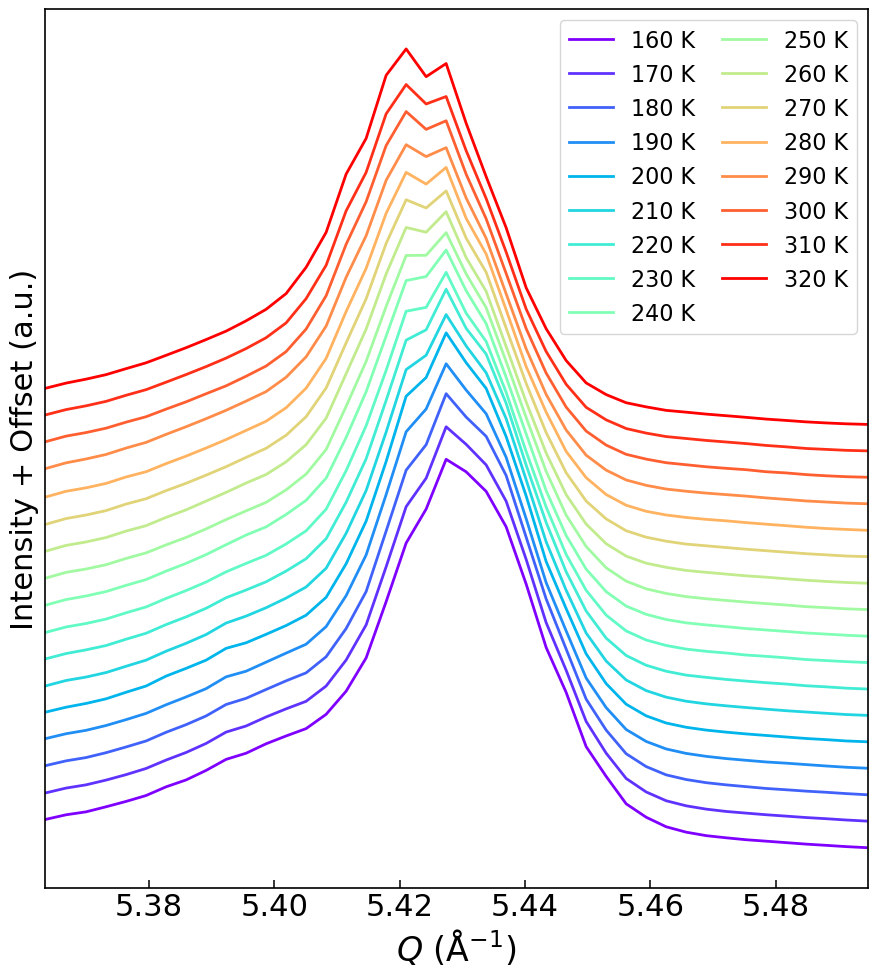

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re

# ====================================================
# User parameters
# ====================================================

# 2theta range (degrees)
theta_min = 8.15
theta_max = 8.35

# Temperature range (K)
T_min = 160
T_max = 320

# Wavelength (Angstrom)
wavelength = 0.1665

# Number of header lines
header_lines = 3

# --- Waterfall Offset Parameter ---
# Adjust this vertical step size based on your peak intensities
vertical_step = 50000

# ====================================================
# Read all files in current directory
# ====================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")

if len(files) == 0:
    raise FileNotFoundError("No .xye or .xye.txt files found.")

# ====================================================
# Containers
# ====================================================

temps = []
patterns = []

# ====================================================
# Read every file
# ====================================================

for file in files:

    filename = os.path.basename(file)

    # --------------------------------------------
    # Extract temperature
    # --------------------------------------------
    m = re.search(r'_(\d+(?:\.\d+)?)K', filename)

    if m is None:
        print(f"Temperature not found in {filename}")
        continue

    T = float(m.group(1))

    # Temperature filter
    if (T < T_min) or (T > T_max):
        continue

    # --------------------------------------------
    # Filter for 10 K intervals
    # --------------------------------------------
    if not np.isclose(T % 10, 0, atol=0.5) and \
       not np.isclose(T % 10, 10, atol=0.5):
        continue

    # --------------------------------------------
    # Read XYE file
    # --------------------------------------------
    data = np.loadtxt(file, skiprows=header_lines)

    two_theta = data[:, 0]
    intensity = data[:, 1]

    # --------------------------------------------
    # 2theta range
    # --------------------------------------------
    mask = (
        (two_theta >= theta_min) &
        (two_theta <= theta_max)
    )

    two_theta = two_theta[mask]
    intensity = intensity[mask]

    if len(two_theta) == 0:
        print(f"No data in chosen theta range for {filename}")
        continue

    # --------------------------------------------
    # Convert 2theta -> Q
    #
    # Q = (4*pi/lambda) * sin(theta)
    # theta = 2theta / 2
    # --------------------------------------------

    theta_rad = np.deg2rad(two_theta / 2.0)

    Q = (
        4.0 * np.pi / wavelength
        * np.sin(theta_rad)
    )

    temps.append(T)
    patterns.append((T, Q, intensity))

# ====================================================
# Sort by temperature
# ====================================================

temps = np.array(temps)

idx = np.argsort(temps)

temps = temps[idx]
patterns = [patterns[i] for i in idx]

# ====================================================
# Q-axis limits
# ====================================================

Q_min = (
    4.0 * np.pi / wavelength
    * np.sin(np.deg2rad(theta_min / 2.0))
)

Q_max = (
    4.0 * np.pi / wavelength
    * np.sin(np.deg2rad(theta_max / 2.0))
)

print(f"Q range: {Q_min:.5f} - {Q_max:.5f} Å⁻¹")

# ====================================================
# Publication-style plotting parameters
# ====================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 14,
    "axes.linewidth": 1.2,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.width": 1.1,
    "ytick.major.width": 1.1,
    "xtick.major.size": 6,
    "ytick.major.size": 6,
})

# ====================================================
# Plot all diffraction patterns (Waterfall Style)
# ====================================================

fig, ax = plt.subplots(figsize=(9, 10))

colors = plt.get_cmap("rainbow")(
    np.linspace(0, 1, len(patterns))
)

for i, (T, Q, intensity) in enumerate(patterns):

    # Cumulative upward shift
    shifted_intensity = intensity + (i * vertical_step)

    ax.plot(
        Q,
        shifted_intensity,
        lw=2.0,
        color=colors[i],
        label=f"{T:.0f} K"
    )

# ====================================================
# Axis labels and limits
# ====================================================

ax.set_xlabel(
    r"$Q$ ($\mathrm{\AA}^{-1}$)",
    fontsize=24
)

ax.set_ylabel(
    "Intensity + Offset (a.u.)",
    fontsize=22
)

ax.set_xlim(Q_min, Q_max)

# No arbitrary intensity ticks because of waterfall offsets
ax.set_yticks([])

ax.tick_params(
    axis="both",
    which="major",
    labelsize=22
)

# ====================================================
# Legend
# ====================================================

ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.0, 1.0),
    fontsize=16,
    frameon=True,
    ncol=2,
    handlelength=2.0,
    columnspacing=1.2
)

# ====================================================
# Clean publication-style frame
# ====================================================

ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)
ax.spines["left"].set_visible(True)
ax.spines["bottom"].set_visible(True)

plt.tight_layout()

# ====================================================
# Save figure
# ====================================================

plt.savefig(
    "XRD_TemperatureSeries_Waterfall_Q.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Found 74 XYE files.


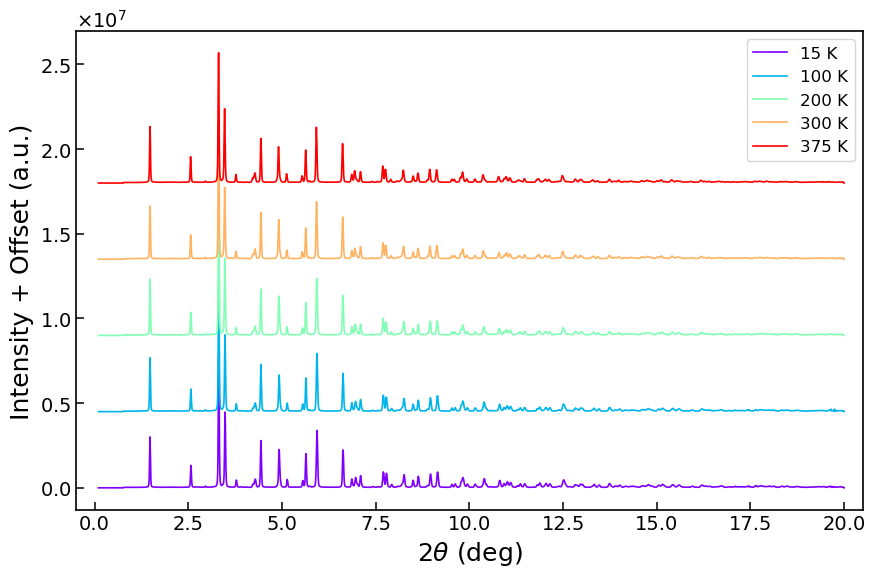

In [49]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re
from matplotlib.ticker import ScalarFormatter

# ====================================================
# User parameters
# ====================================================

# 2theta range (deg)
theta_min = -0.5
theta_max = 20.5

# Specific temperatures to plot (K)
target_temperatures = [15, 100, 200, 300, 375]

# Temperature matching tolerance (K)
temperature_tolerance = 0.5

# Number of header lines
header_lines = 3

# Waterfall vertical offset
vertical_step = 4500000

# ====================================================
# Read all files in current directory
# ====================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")

if len(files) == 0:
    raise FileNotFoundError("No .xye or .xye.txt files found.")

# ====================================================
# Container
# ====================================================

patterns = []

# ====================================================
# Read files
# ====================================================

for file in files:

    filename = os.path.basename(file)

    # --------------------------------------------
    # Extract temperature from filename
    # --------------------------------------------
    m = re.search(r'_(\d+(?:\.\d+)?)K', filename)

    if m is None:
        print(f"Temperature not found in {filename}")
        continue

    T = float(m.group(1))

    # --------------------------------------------
    # Keep only specified temperatures
    # --------------------------------------------
    matched_temperature = None

    for target_T in target_temperatures:
        if np.isclose(T, target_T, atol=temperature_tolerance):
            matched_temperature = target_T
            break

    if matched_temperature is None:
        continue

    # --------------------------------------------
    # Read XYE file
    # --------------------------------------------
    data = np.loadtxt(file, skiprows=header_lines)

    theta = data[:, 0]
    intensity = data[:, 1]

    # --------------------------------------------
    # Restrict to 2theta range
    # --------------------------------------------
    mask = (theta >= theta_min) & (theta <= theta_max)

    theta = theta[mask]
    intensity = intensity[mask]

    if len(theta) == 0:
        print(f"No data in 2theta range for {filename}")
        continue

    # Store
    patterns.append(
        (matched_temperature, theta, intensity, filename)
    )

# ====================================================
# Check whether all requested temperatures were found
# ====================================================

found_temperatures = [p[0] for p in patterns]

for T in target_temperatures:
    if T not in found_temperatures:
        print(f"WARNING: No file found for {T} K")

if len(patterns) == 0:
    raise ValueError("No files found for the specified temperatures.")

# ====================================================
# Sort by temperature
# ====================================================

patterns.sort(key=lambda x: x[0])

# ====================================================
# Plot diffraction patterns — Waterfall Style
# ====================================================

fig, ax = plt.subplots(figsize=(9, 6))

colors = plt.get_cmap('rainbow')(
    np.linspace(0, 1, len(patterns))
)

for i, (T, theta, intensity, filename) in enumerate(patterns):

    # --------------------------------------------
    # Apply vertical offset
    # --------------------------------------------
    shifted_intensity = intensity + i * vertical_step

    ax.plot(
        theta,
        shifted_intensity,
        lw=1.2,
        color=colors[i],
        label=f"{T:.0f} K"
    )

# ====================================================
# Plot formatting
# ====================================================

ax.set_xlabel(r"$2\theta$ (deg)", fontsize=18)

ax.set_ylabel(
    r"Intensity + Offset (a.u.)",
    fontsize=18
)

ax.set_xlim(theta_min, theta_max)

ax.tick_params(
    axis='both',
    labelsize=14
)

# ====================================================
# Scientific notation on Y-axis
# ====================================================

formatter = ScalarFormatter(useMathText=True)
formatter.set_scientific(True)
formatter.set_powerlimits((0, 0))

ax.yaxis.set_major_formatter(formatter)

# Force scientific notation such as ×10^6
ax.ticklabel_format(
    axis='y',
    style='sci',
    scilimits=(0, 0)
)

# ====================================================
# Legend
# ====================================================

ax.legend(
    loc='upper right',
    fontsize=12,
    frameon=True
)

plt.tight_layout()

# ====================================================
# Save figure
# ====================================================

plt.savefig(
    "XRD_Selected_Temperatures_0-20deg_Waterfall.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Found 74 XYE files.


/tmp/ipykernel_3969033/2344186361.py:142: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


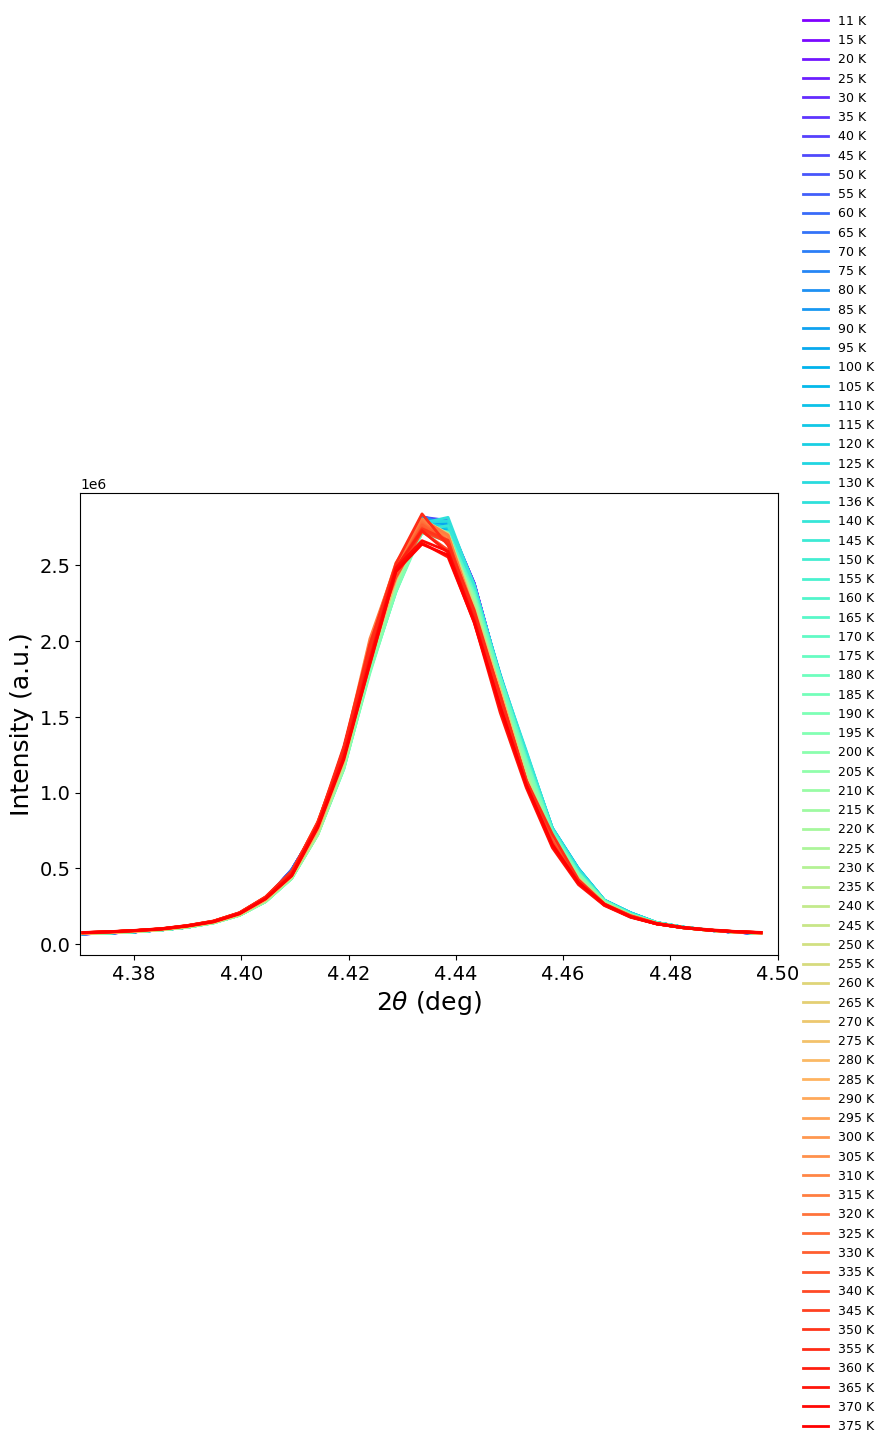

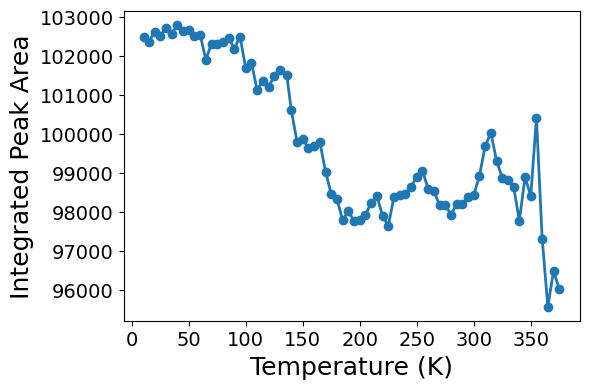

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re

# ====================================================
# User parameters
# ====================================================

# 2theta range
theta_min = 4.37
theta_max = 4.50

# Temperature range (K)
T_min = 11
T_max = 380

# Number of header lines
header_lines = 3

# ====================================================
# Read all files in current directory
# ====================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")

if len(files) == 0:
    raise FileNotFoundError("No .xye or .xye.txt files found.")

# ====================================================
# Containers
# ====================================================

temps = []
areas = []
patterns = []

# ====================================================
# Read every file
# ====================================================

for file in files:

    filename = os.path.basename(file)

    # --------------------------------------------
    # Extract temperature
    # --------------------------------------------
    m = re.search(r'_(\d+(?:\.\d+)?)K', filename)

    if m is None:
        print(f"Temperature not found in {filename}")
        continue

    T = float(m.group(1))

    # Temperature filter
    if (T < T_min) or (T > T_max):
        continue

    # --------------------------------------------
    # Read XYE file
    # --------------------------------------------
    data = np.loadtxt(file, skiprows=header_lines)

    theta = data[:, 0]
    intensity = data[:, 1]

    # --------------------------------------------
    # Theta range
    # --------------------------------------------
    mask = (theta >= theta_min) & (theta <= theta_max)

    theta = theta[mask]
    intensity = intensity[mask]

    if len(theta) == 0:
        print(f"No data in chosen theta range for {filename}")
        continue

    # --------------------------------------------
    # Integrated area
    # --------------------------------------------
    area = np.trapezoid(intensity, x=theta)

    temps.append(T)
    areas.append(area)

    patterns.append((T, theta, intensity))

# ====================================================
# Sort by temperature
# ====================================================

temps = np.array(temps)
areas = np.array(areas)

idx = np.argsort(temps)

temps = temps[idx]
areas = areas[idx]
patterns = [patterns[i] for i in idx]

# ====================================================
# Plot all diffraction patterns
# ====================================================

plt.figure(figsize=(9,6))

colors = plt.get_cmap('rainbow')(np.linspace(0,1,len(patterns)))

for i,(T,theta,intensity) in enumerate(patterns):

    plt.plot(
        theta,
        intensity,
        lw=2,
        color=colors[i],
        label=f"{T:.0f} K"
    )

plt.xlabel(r"$2\theta$ (deg)", fontsize=18)
plt.ylabel("Intensity (a.u.)", fontsize=18)

plt.xlim(theta_min, theta_max)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(
    loc='center left',
    bbox_to_anchor=(1.02,0.5),
    fontsize=9,
    frameon=False,
    ncol=1
)

plt.tight_layout()

plt.savefig(
    "XRD_TemperatureSeries.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# ====================================================
# Plot Integrated Area vs Temperature
# ====================================================

plt.figure(figsize=(6,4))

plt.plot(
    temps,
    areas,
    '-o',
    linewidth=2,
    markersize=6
)

plt.xlabel("Temperature (K)", fontsize=18)
plt.ylabel("Integrated Peak Area", fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.tight_layout()

plt.savefig(
    "IntegratedArea_vs_Temperature.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

Found 74 XYE files.
300 K file found: Sr2IrO4_Tseries_XRD_20260624-061442_6e6157_300K_sub_1.xye


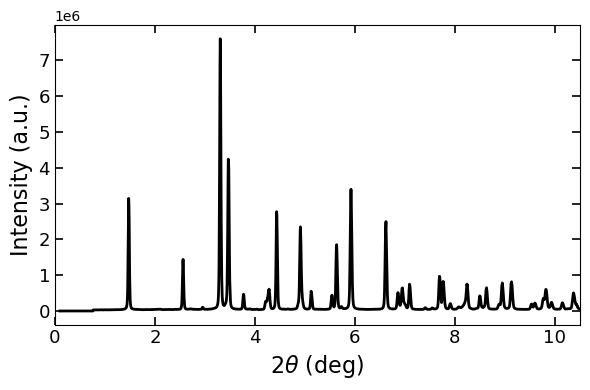

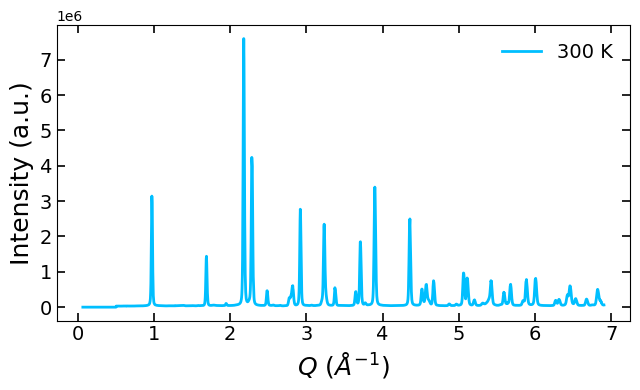

In [26]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import re


# ====================================================
# User parameters
# ====================================================

# 2theta range
theta_min = 0.0
theta_max = 10.5

# Target temperature
target_temperature = 300

# X-ray wavelength (Angstrom)
wavelength = 0.1665     # Cu K-alpha


# Number of header lines
header_lines = 3



# ====================================================
# Read files
# ====================================================

files = glob.glob("*.xye")
files += glob.glob("*.xye.txt")

print(f"Found {len(files)} XYE files.")


if len(files) == 0:
    raise FileNotFoundError(
        "No .xye or .xye.txt files found."
    )


# ====================================================
# Find 300 K file
# ====================================================

xrd_300K = None


for file in files:

    filename = os.path.basename(file)

    m = re.search(
        r'_(\d+(?:\.\d+)?)K',
        filename
    )

    if m is None:
        continue


    T = float(m.group(1))


    if abs(T-target_temperature) < 1e-3:

        print("300 K file found:", filename)

        data = np.loadtxt(
            file,
            skiprows=header_lines
        )

        xrd_300K = data

        break



if xrd_300K is None:
    raise FileNotFoundError(
        "No 300 K XRD file found."
    )



# ====================================================
# Extract data
# ====================================================

two_theta = xrd_300K[:,0]
intensity = xrd_300K[:,1]


# Select desired range

mask = (
    (two_theta >= theta_min) &
    (two_theta <= theta_max)
)


two_theta = two_theta[mask]
intensity = intensity[mask]



# ====================================================
# Convert 2theta to Q
# ====================================================

theta_rad = np.deg2rad(two_theta/2)


Q = (
    4*np.pi/wavelength
    *
    np.sin(theta_rad)
)



# ====================================================
# Plot Intensity vs 2theta
# ====================================================

plt.figure(figsize=(6,4))

plt.plot(
    two_theta,
    intensity,
    color="black",
    linewidth=2
)


plt.xlabel(
    r"$2\theta$ (deg)",
    fontsize=16
)

plt.ylabel(
    "Intensity (a.u.)",
    fontsize=16
)


plt.xticks(
    fontsize=13
)

plt.yticks(
    fontsize=13
)


plt.xlim(
    theta_min,
    theta_max
)


# publication style ticks

plt.tick_params(
    direction="in",
    length=6,
    width=1.2,
    top=True,
    right=True
)


plt.tight_layout()


plt.savefig(
    "XRD_300K_2theta.png",
    dpi=600,
    bbox_inches="tight"
)


plt.show()



# ====================================================
# Plot Intensity vs Q
# ====================================================

plt.figure(figsize=(6.5,4))


plt.plot(
    Q,
    intensity,
    color="deepskyblue",
    linewidth=2,
    label="300 K"
)


plt.xlabel(
    r"$Q$ ($\AA^{-1}$)",
    fontsize=18
)


plt.ylabel(
    "Intensity (a.u.)",
    fontsize=18
)



plt.xticks(
    fontsize=14
)

plt.yticks(
    fontsize=14
)



plt.tick_params(
    direction="in",
    length=6,
    width=1.2,
    top=True,
    right=True
)

plt.legend(
    fontsize=14,
    frameon=False,
    loc="best"
)


plt.tight_layout()


plt.savefig(
    "XRD_300K_Q.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

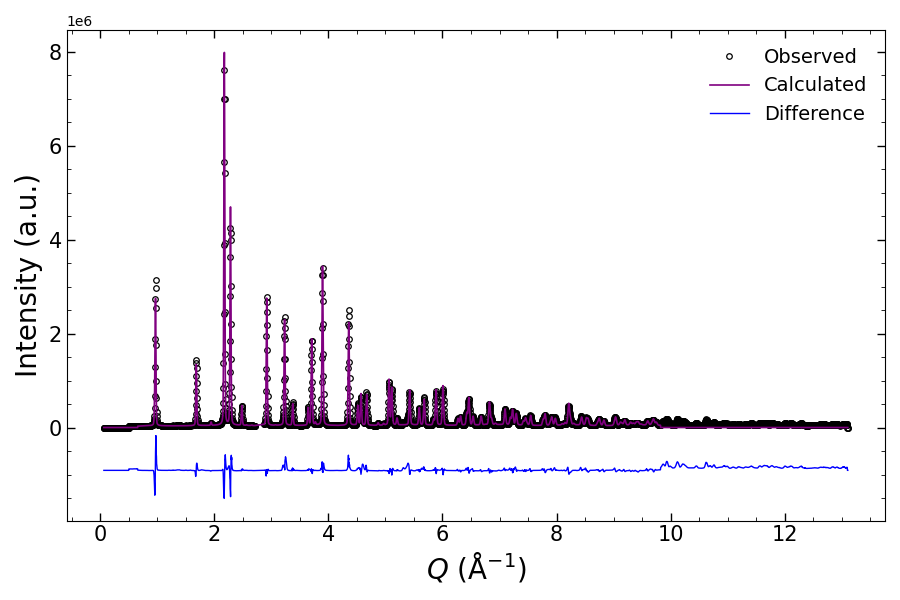

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib widget

# ============================================================
# USER SETTINGS
# ============================================================

excel_file = "Sr2IrO4_Tseries_V1_Refined_300 K.xlsx"

# ------------------------------------------------------------
# Excel columns
# ------------------------------------------------------------

Q_column = "Q"
observed_column = "y_obs"
calculated_column = "y_calc"
background_column = "y_bkg"


# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------

# Vertical position of the difference curve
difference_offset = None
# None = automatically determine a suitable offset

# Observed marker size
marker_size = 4

# Calculated line width
calculated_linewidth = 1.2

# Difference line width
difference_linewidth = 1.0


# ============================================================
# LOAD EXCEL DATA
# ============================================================

df = pd.read_excel(excel_file)


# ============================================================
# CHECK REQUIRED COLUMNS
# ============================================================

required_columns = {
    Q_column,
    observed_column,
    calculated_column
}

missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"Missing required Excel columns: {missing}"
    )


# ============================================================
# EXTRACT DATA
# ============================================================

Q = pd.to_numeric(
    df[Q_column],
    errors="coerce"
).to_numpy()

y_obs = pd.to_numeric(
    df[observed_column],
    errors="coerce"
).to_numpy()

y_calc = pd.to_numeric(
    df[calculated_column],
    errors="coerce"
).to_numpy()


# ============================================================
# REMOVE INVALID VALUES
# ============================================================

valid = (
    np.isfinite(Q)
    & np.isfinite(y_obs)
    & np.isfinite(y_calc)
)

Q = Q[valid]
y_obs = y_obs[valid]
y_calc = y_calc[valid]


# ============================================================
# SORT ACCORDING TO Q
# ============================================================

sort_index = np.argsort(Q)

Q = Q[sort_index]
y_obs = y_obs[sort_index]
y_calc = y_calc[sort_index]


# ============================================================
# CALCULATE DIFFERENCE
#
# Difference = Observed - Calculated
# ============================================================

difference = y_obs - y_calc


# ============================================================
# DETERMINE DIFFERENCE OFFSET
# ============================================================

if difference_offset is None:

    intensity_range = (
        np.nanmax(y_obs) -
        np.nanmin(y_obs)
    )

    difference_offset = (
        np.nanmin(y_obs)
        - 0.12 * intensity_range
    )


# Shift difference curve downward
difference_plot = (
    difference + difference_offset
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 6)
)


# ============================================================
# OBSERVED DATA
# ============================================================

ax.plot(
    Q,
    y_obs,
    linestyle="none",
    marker="o",
    markersize=marker_size,
    markerfacecolor="none",
    markeredgecolor="black",
    markeredgewidth=0.9,
    label="Observed"
)


# ============================================================
# CALCULATED PROFILE
# ============================================================

ax.plot(
    Q,
    y_calc,
    color="purple",
    linewidth=calculated_linewidth,
    label="Calculated"
)


# ============================================================
# DIFFERENCE
# ============================================================

ax.plot(
    Q,
    difference_plot,
    color="blue",
    linewidth=difference_linewidth,
    label="Difference"
)


# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(
    r"$Q$ ($\mathrm{\AA}^{-1}$)",
    fontsize=20
)

ax.set_ylabel(
    r"Intensity (a.u.)",
    fontsize=20
)


# ============================================================
# TICK SETTINGS
# ============================================================

ax.tick_params(
    axis="both",
    which="major",
    labelsize=15,
    direction="in",
    length=6,
    width=1.0,
    top=True,
    right=True
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3,
    top=True,
    right=True
)

ax.minorticks_on()


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    fontsize=14,
    frameon=False,
    loc="upper right"
)


# ============================================================
# NO GRID
# ============================================================

ax.grid(False)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# SHOW
# ============================================================

plt.show()

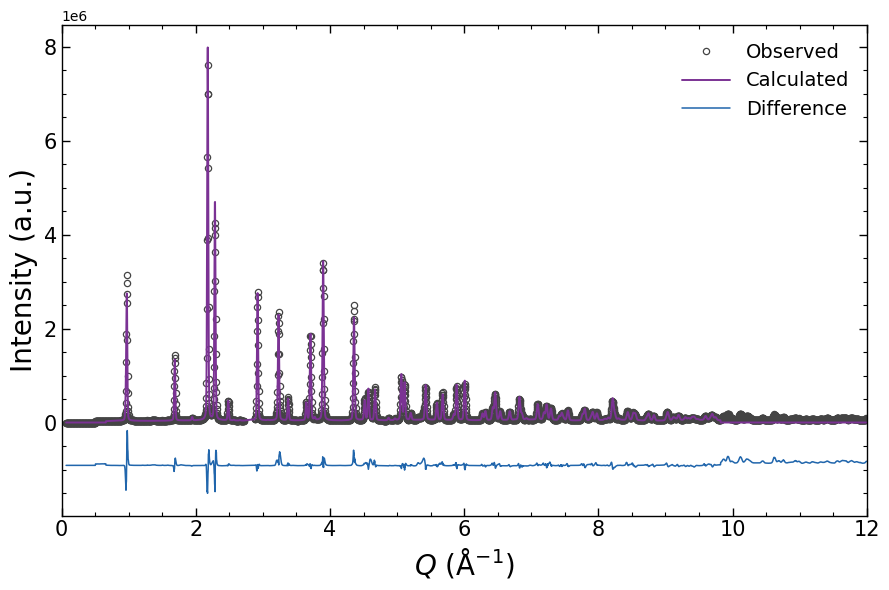

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# USER SETTINGS
# ============================================================

excel_file = "Sr2IrO4_Tseries_V1_Refined_300 K.xlsx"


# ------------------------------------------------------------
# Excel columns
# ------------------------------------------------------------

Q_column = "Q"
observed_column = "y_obs"
calculated_column = "y_calc"
background_column = "y_bkg"


# ------------------------------------------------------------
# Q range
# ------------------------------------------------------------

Q_min = 0
Q_max = 12


# ------------------------------------------------------------
# Plot settings
# ------------------------------------------------------------

# Vertical position of the difference curve
difference_offset = None
# None = automatically determine a suitable offset


# Observed marker
marker_size = 4.5
observed_color = "#444444"       # dark grey
observed_linewidth = 0.9


# Calculated profile
calculated_color = "#7B3294"     # publication-style purple
calculated_linewidth = 1.4


# Difference profile
difference_color = "#2166AC"     # publication-style blue
difference_linewidth = 1.1


# ============================================================
# LOAD EXCEL DATA
# ============================================================

df = pd.read_excel(excel_file)


# ============================================================
# CHECK REQUIRED COLUMNS
# ============================================================

required_columns = {
    Q_column,
    observed_column,
    calculated_column
}

missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"Missing required Excel columns: {missing}"
    )


# ============================================================
# EXTRACT DATA
# ============================================================

Q = pd.to_numeric(
    df[Q_column],
    errors="coerce"
).to_numpy()

y_obs = pd.to_numeric(
    df[observed_column],
    errors="coerce"
).to_numpy()

y_calc = pd.to_numeric(
    df[calculated_column],
    errors="coerce"
).to_numpy()


# ============================================================
# REMOVE INVALID VALUES
# ============================================================

valid = (
    np.isfinite(Q)
    & np.isfinite(y_obs)
    & np.isfinite(y_calc)
)

Q = Q[valid]
y_obs = y_obs[valid]
y_calc = y_calc[valid]


# ============================================================
# RESTRICT DATA TO Q = 0–12 Å⁻¹
# ============================================================

q_mask = (
    (Q >= Q_min)
    & (Q <= Q_max)
)

Q = Q[q_mask]
y_obs = y_obs[q_mask]
y_calc = y_calc[q_mask]


# ============================================================
# SORT ACCORDING TO Q
# ============================================================

sort_index = np.argsort(Q)

Q = Q[sort_index]
y_obs = y_obs[sort_index]
y_calc = y_calc[sort_index]


# ============================================================
# CALCULATE DIFFERENCE
#
# Difference = Observed - Calculated
# ============================================================

difference = y_obs - y_calc


# ============================================================
# DETERMINE DIFFERENCE OFFSET
# ============================================================

if difference_offset is None:

    intensity_range = (
        np.nanmax(y_obs) -
        np.nanmin(y_obs)
    )

    difference_offset = (
        np.nanmin(y_obs)
        - 0.12 * intensity_range
    )


# Shift difference curve downward
difference_plot = (
    difference + difference_offset
)


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(9.0, 6.0)
)


# ============================================================
# OBSERVED DATA
# ============================================================

ax.plot(
    Q,
    y_obs,

    linestyle="none",

    marker="o",

    markersize=marker_size,

    markerfacecolor="none",

    markeredgecolor=observed_color,

    markeredgewidth=observed_linewidth,

    label="Observed"
)


# ============================================================
# CALCULATED PROFILE
# ============================================================

ax.plot(
    Q,
    y_calc,

    color=calculated_color,

    linewidth=calculated_linewidth,

    solid_capstyle="round",

    label="Calculated"
)


# ============================================================
# DIFFERENCE
# ============================================================

ax.plot(
    Q,
    difference_plot,

    color=difference_color,

    linewidth=difference_linewidth,

    solid_capstyle="round",

    label="Difference"
)


# ============================================================
# AXIS LIMITS
# ============================================================

ax.set_xlim(
    Q_min,
    Q_max
)


# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(
    r"$Q$ ($\mathrm{\AA}^{-1}$)",
    fontsize=20
)

ax.set_ylabel(
    r"Intensity (a.u.)",
    fontsize=20
)


# ============================================================
# TICK SETTINGS
# ============================================================

ax.tick_params(
    axis="both",
    which="major",
    labelsize=15,

    direction="in",

    length=6,
    width=1.0,

    top=True,
    right=True
)

ax.tick_params(
    axis="both",
    which="minor",

    direction="in",

    length=3,
    width=0.8,

    top=True,
    right=True
)

ax.minorticks_on()


# ============================================================
# SPINES
# ============================================================

for spine in ax.spines.values():

    spine.set_linewidth(1.0)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    fontsize=14,

    frameon=False,

    loc="upper right",

    handlelength=2.5
)


# ============================================================
# NO GRID
# ============================================================

ax.grid(False)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# SAVE AS PNG
# ============================================================

plt.savefig(
    "Sr2IrO4_Rietveld_Refinement_Q_300K.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)


# ============================================================
# SHOW
# ============================================================

plt.show()

Reading refined crystal structure from CIF...
Space group: I 41/a c d:2
Unit cell: a=5.49517 Å, b=5.49517 Å, c=25.80730 Å

Calculated 179 Bragg reflections.
 h  k  l      d_A   Q_A^-1    intensity
 0  0  4 6.451825 0.973862 4.706750e+06
 1  1  2 3.720640 1.688738 2.966428e+06
 0  0  8 3.225913 1.947723 2.069664e+06
 1  1  6 2.883333 2.179139 8.217932e+06
 2  0  0 2.747585 2.286803 9.691042e+06
 2  0  4 2.527903 2.485533 2.408305e+06
 2  1  1 2.446448 2.568289 3.528352e+03
 2  1  3 2.362983 2.659006 3.369571e+03
 2  1  5 2.218847 2.831734 3.081696e+03
 0  0 12 2.150608 2.921585 9.068021e+06
 1  1 10 2.149775 2.922717 4.213303e+06
 2  0  8 2.091713 3.003847 1.015118e+06
 2  1  7 2.044859 3.072675 2.712999e+03
 2  2  0 1.942836 3.234028 9.238447e+06
 2  1  9 1.865988 3.367216 2.314678e+03
 2  2  4 1.860320 3.377476 2.822007e+06
 3  1  2 1.722179 3.648393 2.095985e+06
 2  1 11 1.696971 3.702588 1.928419e+03
 2  0 12 1.693518 3.710138 6.159212e+06
 1  1 14 1.665467 3.772627 1.250966e+06
 2 

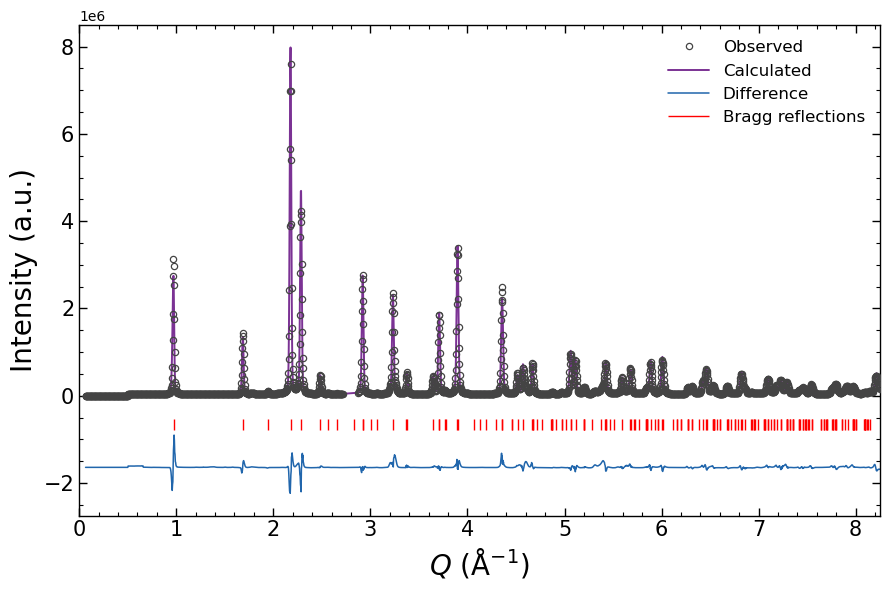

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gemmi


# ============================================================
# USER SETTINGS
# ============================================================

excel_file = "Sr2IrO4_Tseries_V1_Refined_300 K.xlsx"

cif_file = "Sr2IrO4_Tseries_300K_Refined.cif"


# ------------------------------------------------------------
# Excel columns
# ------------------------------------------------------------

Q_column = "Q"
observed_column = "y_obs"
calculated_column = "y_calc"
background_column = "y_bkg"


# ------------------------------------------------------------
# Q range (Å^-1)
# ------------------------------------------------------------

Q_min = 0.0
Q_max = 8.25


# ------------------------------------------------------------
# X-ray wavelength (Å)
# ------------------------------------------------------------

wavelength = 1.5406


# ------------------------------------------------------------
# Difference curve offset
# ------------------------------------------------------------

difference_offset = None

# Additional downward shift as a fraction of the observed
# intensity range.
extra_difference_shift_fraction = 0.15


# ------------------------------------------------------------
# Bragg reflection marker settings
# ------------------------------------------------------------

peak_color = "red"
peak_linewidth = 1.0

# Height of all red ticks as a fraction of the observed
# intensity range.
peak_height_fraction = 0.035

# Common vertical placement of all red ticks.
# Increase this value to move all ticks upward.
peak_vertical_position_fraction = 0.65

# Maximum number of reflections.
# None means retain all calculated reflections.
max_reflections = None


# ------------------------------------------------------------
# Observed markers
# ------------------------------------------------------------

marker_size = 4.5
observed_color = "#444444"
observed_linewidth = 0.9


# ------------------------------------------------------------
# Calculated profile
# ------------------------------------------------------------

calculated_color = "#7B3294"
calculated_linewidth = 1.4


# ------------------------------------------------------------
# Difference profile
# ------------------------------------------------------------

difference_color = "#2166AC"
difference_linewidth = 1.1


# ============================================================
# LOAD CIF AND READ CRYSTAL STRUCTURE
# ============================================================

print("Reading refined crystal structure from CIF...")

structure = gemmi.read_small_structure(cif_file)

cell = structure.cell
spacegroup = structure.spacegroup

if spacegroup is None:
    raise ValueError(
        "The CIF does not specify a recognizable space group. "
        "Please check the CIF symmetry information."
    )

print(f"Space group: {spacegroup.xhm()}")

print(
    "Unit cell: "
    f"a={cell.a:.5f} Å, "
    f"b={cell.b:.5f} Å, "
    f"c={cell.c:.5f} Å"
)


# ============================================================
# GENERATE BRAGG REFLECTIONS
# ============================================================

cell_volume = cell.volume

if cell_volume <= 0:
    raise ValueError("Invalid unit-cell volume in the CIF.")

# Q = 2*pi/d
d_min = 2.0 * np.pi / Q_max

reciprocal_cell = cell.reciprocal()

hmax = max(
    int(np.ceil(Q_max * reciprocal_cell.a / (2.0 * np.pi))) + 2,
    1
)

kmax = max(
    int(np.ceil(Q_max * reciprocal_cell.b / (2.0 * np.pi))) + 2,
    1
)

lmax = max(
    int(np.ceil(Q_max * reciprocal_cell.c / (2.0 * np.pi))) + 2,
    1
)

# Generate symmetry-allowed unique reflections.
reflections = gemmi.make_miller_array(
    cell,
    spacegroup,
    d_min,
    unique=True
)

# Calculate X-ray structure factors.
sf_calculator = gemmi.StructureFactorCalculatorX(cell)

reflection_records = []

for hkl in reflections:

    h, k, l = map(int, hkl)

    # Exclude the direct beam (000).
    if h == 0 and k == 0 and l == 0:
        continue

    # Calculate d-spacing.
    d_spacing = cell.calculate_d([h, k, l])

    if not np.isfinite(d_spacing) or d_spacing <= 0:
        continue

    # Calculate Q position.
    Q_reflection = 2.0 * np.pi / d_spacing

    if not (Q_min <= Q_reflection <= Q_max):
        continue

    # Calculate structure factor from the CIF atomic model.
    try:
        structure_factor = (
            sf_calculator.calculate_sf_from_small_structure(
                structure,
                [h, k, l]
            )
        )

        intensity = abs(structure_factor) ** 2

    except Exception:
        continue

    if not np.isfinite(intensity) or intensity <= 0:
        continue

    # Apply Bragg-angle accessibility condition.
    sin_theta = (
        Q_reflection * wavelength / (4.0 * np.pi)
    )

    if sin_theta > 1.0:
        continue

    two_theta = 2.0 * np.degrees(
        np.arcsin(sin_theta)
    )

    reflection_records.append({
        "h": h,
        "k": k,
        "l": l,
        "d_A": d_spacing,
        "Q_A^-1": Q_reflection,
        "two_theta_deg": two_theta,
        "intensity": intensity
    })


if not reflection_records:
    raise ValueError(
        "No Bragg reflections were generated. "
        "Check the CIF, Q range, and wavelength."
    )


reflection_df = pd.DataFrame(reflection_records)

reflection_df = reflection_df.sort_values(
    "Q_A^-1"
).reset_index(drop=True)


# ============================================================
# FILTER NEGLIGIBLE REFLECTIONS
# ============================================================

relative_intensity_threshold = 1e-6

strongest_intensity = reflection_df["intensity"].max()

reflection_df = reflection_df[
    reflection_df["intensity"]
    >= relative_intensity_threshold * strongest_intensity
].copy()

reflection_df = reflection_df.sort_values(
    "Q_A^-1"
).reset_index(drop=True)


if max_reflections is not None:
    reflection_df = reflection_df.head(max_reflections)


peak_positions = reflection_df["Q_A^-1"].to_numpy()


print(
    f"\nCalculated {len(peak_positions)} Bragg reflections."
)

print(
    reflection_df[
        ["h", "k", "l", "d_A", "Q_A^-1", "intensity"]
    ].to_string(index=False)
)


# ============================================================
# LOAD RIETVELD REFINEMENT DATA
# ============================================================

df = pd.read_excel(excel_file)

required_columns = {
    Q_column,
    observed_column,
    calculated_column,
    background_column
}

missing = required_columns - set(df.columns)

if missing:
    raise ValueError(
        f"Missing required Excel columns: {missing}"
    )


# ============================================================
# EXTRACT DATA
# ============================================================

Q = pd.to_numeric(
    df[Q_column],
    errors="coerce"
).to_numpy()

y_obs = pd.to_numeric(
    df[observed_column],
    errors="coerce"
).to_numpy()

y_calc = pd.to_numeric(
    df[calculated_column],
    errors="coerce"
).to_numpy()

y_bkg = pd.to_numeric(
    df[background_column],
    errors="coerce"
).to_numpy()


# ============================================================
# REMOVE INVALID VALUES
# ============================================================

valid = (
    np.isfinite(Q)
    & np.isfinite(y_obs)
    & np.isfinite(y_calc)
    & np.isfinite(y_bkg)
)

Q = Q[valid]
y_obs = y_obs[valid]
y_calc = y_calc[valid]
y_bkg = y_bkg[valid]


# ============================================================
# RESTRICT DATA TO THE PLOTTED Q RANGE
# ============================================================

q_mask = (
    (Q >= Q_min)
    & (Q <= Q_max)
)

Q = Q[q_mask]
y_obs = y_obs[q_mask]
y_calc = y_calc[q_mask]
y_bkg = y_bkg[q_mask]


# ============================================================
# SORT DATA ACCORDING TO Q
# ============================================================

sort_index = np.argsort(Q)

Q = Q[sort_index]
y_obs = y_obs[sort_index]
y_calc = y_calc[sort_index]
y_bkg = y_bkg[sort_index]


# ============================================================
# CALCULATE DIFFERENCE
# ============================================================

difference = y_obs - y_calc


# ============================================================
# DETERMINE DIFFERENCE CURVE OFFSET
# ============================================================

intensity_range = (
    np.nanmax(y_obs) - np.nanmin(y_obs)
)

if intensity_range <= 0:
    intensity_range = max(
        np.nanmax(np.abs(y_obs)),
        1.0
    )


if difference_offset is None:

    difference_offset = (
        np.nanmin(y_obs)
        - 0.12 * intensity_range
    )


# Additional downward shift.
difference_offset -= (
    extra_difference_shift_fraction * intensity_range
)

difference_plot = difference + 0.8*difference_offset


# ============================================================
# CREATE FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(9.0, 6.0)
)


# ============================================================
# OBSERVED DATA
# ============================================================

ax.plot(
    Q,
    y_obs,
    linestyle="none",
    marker="o",
    markersize=marker_size,
    markerfacecolor="none",
    markeredgecolor=observed_color,
    markeredgewidth=observed_linewidth,
    label="Observed",
    zorder=3
)


# ============================================================
# CALCULATED PROFILE
# ============================================================

ax.plot(
    Q,
    y_calc,
    color=calculated_color,
    linewidth=calculated_linewidth,
    solid_capstyle="round",
    label="Calculated",
    zorder=2
)


# ============================================================
# DIFFERENCE PROFILE
# ============================================================

ax.plot(
    Q,
    difference_plot,
    color=difference_color,
    linewidth=difference_linewidth,
    solid_capstyle="round",
    label="Difference",
    zorder=2
)


# ============================================================
# RED BRAGG REFLECTION MARKERS
# ============================================================
#
# All ticks have exactly the same vertical position and height.
# Only their horizontal Q positions vary.
# ============================================================

# Identical height for every tick.
tick_height = peak_height_fraction * intensity_range

# Common vertical position for all ticks.
# This places the ticks slightly higher in the gap.
tick_y = -0.18*(
    np.nanmin(difference_plot)
    + peak_vertical_position_fraction
    * (
        np.nanmax(y_calc)
        - np.nanmin(difference_plot)
    )
)

first_marker = True

for q_peak in peak_positions:

    if not (Q_min <= q_peak <= Q_max):
        continue

    label = (
        "Bragg reflections"
        if first_marker
        else "_nolegend_"
    )

    ax.vlines(
        q_peak,
        tick_y,
        tick_y + tick_height,
        color=peak_color,
        linewidth=peak_linewidth,
        label=label,
        zorder=5
    )

    first_marker = False


# ============================================================
# AXIS LIMITS
# ============================================================

ax.set_xlim(
    Q_min,
    Q_max
)


# ============================================================
# AXIS LABELS
# ============================================================

ax.set_xlabel(
    r"$Q$ ($\mathrm{\AA}^{-1}$)",
    fontsize=20
)

ax.set_ylabel(
    r"Intensity (a.u.)",
    fontsize=20
)


# ============================================================
# TICK SETTINGS
# ============================================================

ax.tick_params(
    axis="both",
    which="major",
    labelsize=15,
    direction="in",
    length=6,
    width=1.0,
    top=True,
    right=True
)

ax.tick_params(
    axis="both",
    which="minor",
    direction="in",
    length=3,
    width=0.8,
    top=True,
    right=True
)

ax.minorticks_on()


# ============================================================
# SPINES
# ============================================================

for spine in ax.spines.values():
    spine.set_linewidth(1.0)


# ============================================================
# LEGEND
# ============================================================

ax.legend(
    fontsize=12,
    frameon=False,
    loc="upper right",
    handlelength=2.5
)


# ============================================================
# NO GRID
# ============================================================

ax.grid(False)


# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout()


# ============================================================
# SAVE AS PNG
# ============================================================

plt.savefig(
    "Sr2IrO4_Rietveld_Refinement_Q_300K_2.png",
    dpi=600,
    bbox_inches="tight",
    facecolor="white"
)


# ============================================================
# SHOW
# ============================================================

plt.show()